# Hedonic Pricing

We often try to predict the price of an asset from its observable characteristics. This is generally called **hedonic pricing**: How do the unit's characteristics determine its market price?

1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.
2. Transform your variables - particularly categorical ones - for use in your regression analysis.
3. Implement an 80/20 train-test split. Put the test data aside.
4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?
5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities?
6. Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?
7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?
8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Jackson Gayeski, Derek Hatherley, Will Morales, Abdullah Rana

**Date:** November 11th, 2026

In [1]:
# q1 - load the CSV included in the repo
# Open this notebook from the repo folder and run the cells in order.

In [2]:
# q1 - cleaning
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('data/pierce_county_house_sales.csv')
print(df.shape)
print(df.dtypes)
print(df.isna().sum())

# All dates are from 2020
df['sale_date'] = pd.to_datetime(df['sale_date'])
df['sale_month'] = df['sale_date'].dt.month

# Waterfront type NA means not waterfront
# View quality NA means no rated view
df['waterfront_type'] = df['waterfront_type'].fillna('Not waterfront')
df['view_quality'] = df['view_quality'].fillna('None')

# drop the rest of the NA rows
df = df.dropna()
print()
print('NA after drops:', df.isna().sum())
print()

# Check for duplicates
print(f'duplicated rows: {df.duplicated().sum()}')
df = df.drop_duplicates()
print(f'duplicated rows after drop: {df.duplicated().sum()}')

print()
print(df.describe())

# Some unrealistic values - drop
df = df[df['sale_price'] >= 50000]
df = df[df['house_square_feet'] >= 100]
df = df[df['bedrooms'] > 0]
df = df[df['bathrooms'] > 0]
df = df[df['stories'] > 0]
print()
print('Cleaned shape:', df.shape)
print()

num_vars = ['sale_price', 'house_square_feet', 'attic_finished_square_feet', 'basement_square_feet',
            'attached_garage_square_feet', 'detached_garage_square_feet', 'fireplaces', 'stories', 'year_built',
            'bedrooms', 'bathrooms']
cat_vars = ['hvac_description', 'exterior', 'interior', 'roof_cover', 'waterfront_type', 'view_quality', 'utility_sewer']
print(df[num_vars].describe().T)
for c in cat_vars:
  print(df[c].value_counts(), '\n')




(16814, 19)
sale_date                      object
sale_price                      int64
house_square_feet               int64
attic_finished_square_feet      int64
basement_square_feet            int64
attached_garage_square_feet     int64
detached_garage_square_feet     int64
fireplaces                      int64
hvac_description               object
exterior                       object
interior                       object
stories                         int64
roof_cover                     object
year_built                      int64
bedrooms                        int64
bathrooms                       int64
waterfront_type                object
view_quality                   object
utility_sewer                  object
dtype: object
sale_date                          0
sale_price                         0
house_square_feet                  0
attic_finished_square_feet         0
basement_square_feet               0
attached_garage_square_feet        0
detached_garage_square_feet   

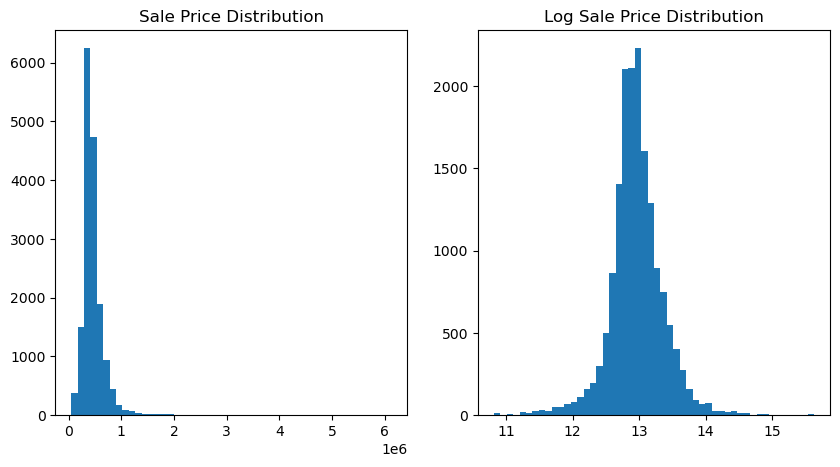

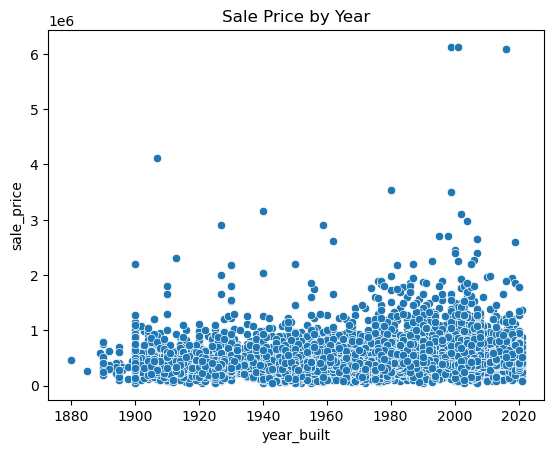

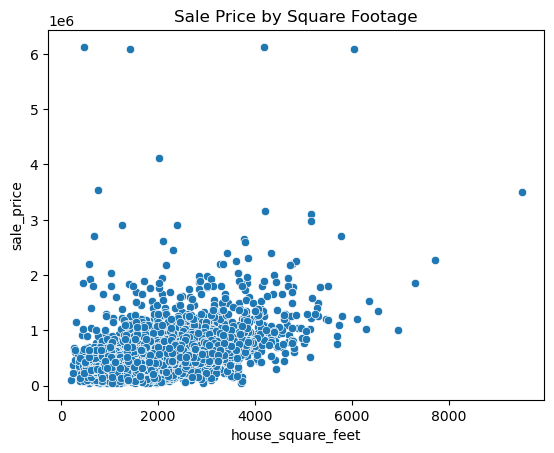

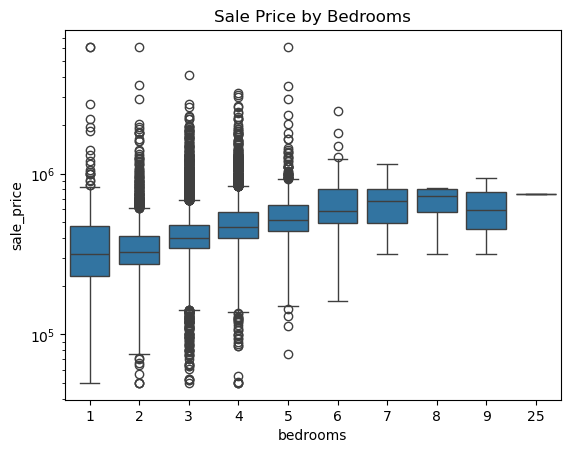

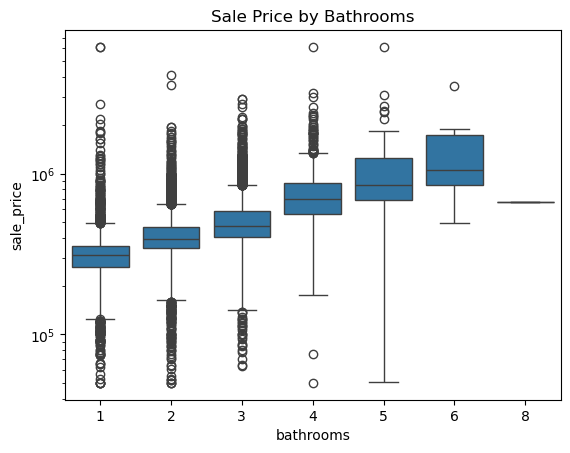

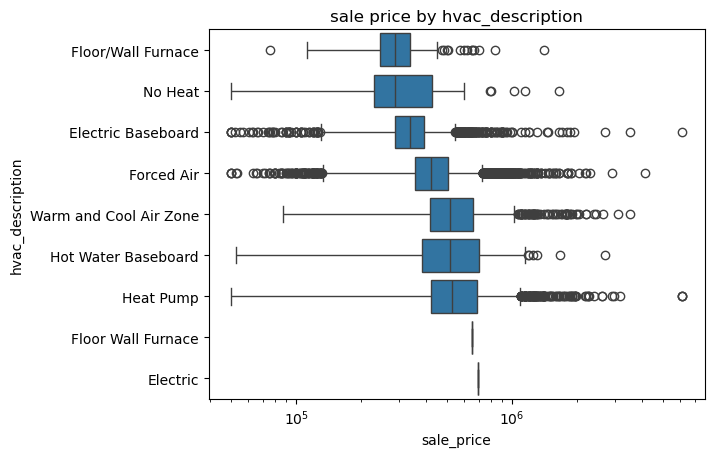

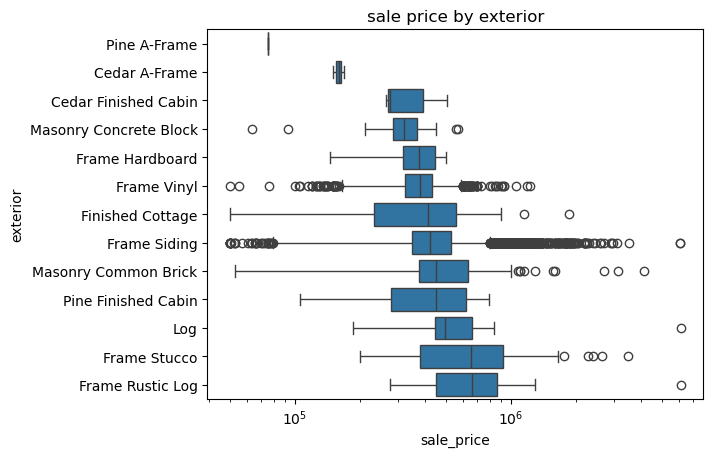

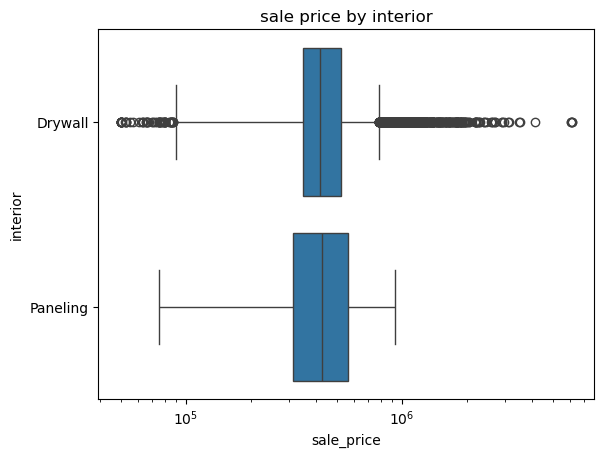

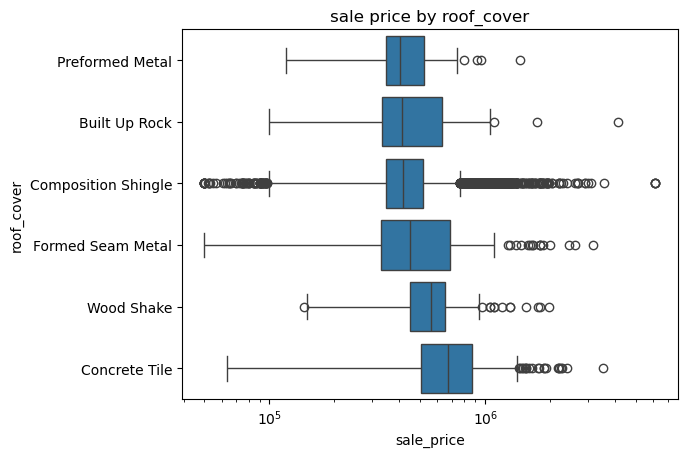

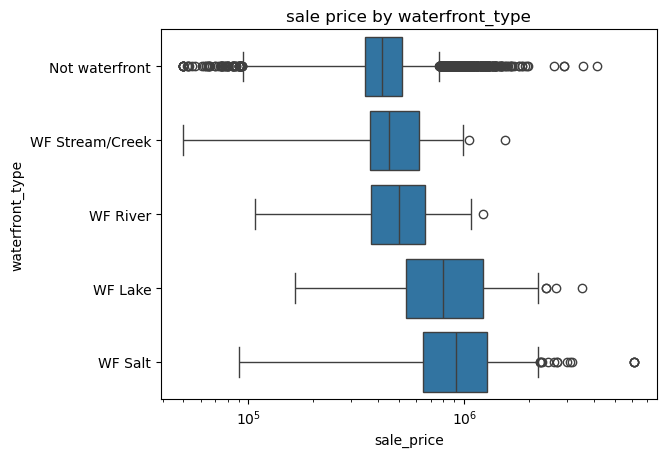

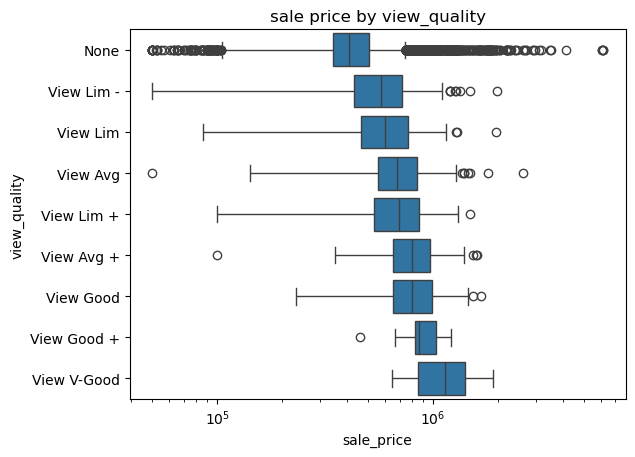

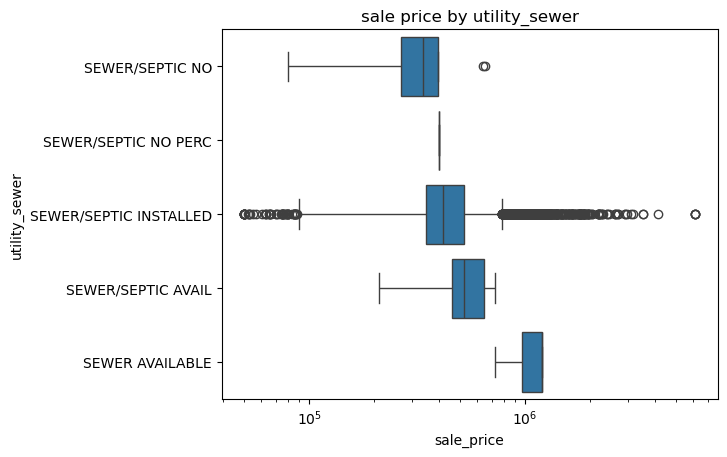

In [3]:
from matplotlib import axes
# q1 Visualization

# Sale price distribution
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
df['sale_price'].hist(bins=50, grid=False, ax=axes[0])
axes[0].set_title('Sale Price Distribution')
np.log(df['sale_price']).hist(bins=50, grid=False, ax=axes[1]) # Sale price is skewed right, graph log transformation
axes[1].set_title('Log Sale Price Distribution')
plt.show()

# Sale price by year
sns.scatterplot(data=df, x='year_built', y='sale_price')
plt.title('Sale Price by Year')
plt.show()

# Sale price by square footage
sns.scatterplot(data=df, x='house_square_feet', y='sale_price')
plt.title('Sale Price by Square Footage')
plt.show()

# Sale price by bedrooms
sns.boxplot(data=df, x='bedrooms', y='sale_price')
plt.title('Sale Price by Bedrooms')
plt.yscale('log')
plt.show()

# Sale price by bathrooms
sns.boxplot(data=df, x='bathrooms', y='sale_price')
plt.yscale('log') # Box plots are skewed heavily by high sale prices - log transform them
plt.title('Sale Price by Bathrooms')
plt.show()

# Price by categorical Features
for c in cat_vars:
  order = df.groupby(c)['sale_price'].median().sort_values().index
  sns.boxplot(data=df, y=c, x='sale_price', order=order)
  plt.xscale('log')
  plt.title(f'sale price by {c}')
  plt.show()

In [4]:
# q2
t_df = df.copy()

# transform skewed numerical values
t_df['log_price'] = np.log(t_df['sale_price'])
t_df['log_sqft'] = np.log(t_df['house_square_feet'])
t_df['age'] = 2020 - t_df['year_built']

# Assign 1 or 0 for features that houses either have or don't have
t_df['has_basement'] = (t_df['basement_square_feet'] > 0).astype(int)
t_df['has_attic'] = (t_df['attic_finished_square_feet'] > 0).astype(int)
t_df['has_attached_garage'] = (t_df['attached_garage_square_feet'] > 0).astype(int)
t_df['has_detached_garage'] = (t_df['detached_garage_square_feet'] > 0).astype(int)

# Simplify waterfront to yes or no
t_df['waterfront'] = (t_df['waterfront_type'] != 'Not waterfront').astype(int)

# Map views to a score rating
view_map = {'None': 0, 'View Lim -': 1, 'View Lim': 2, 'View Lim +': 3,
            'View Avg': 4, 'View Avg +': 5, 'View Good': 6, 'View Good +': 7, 'View V-Good': 8}
t_df['view_score'] = t_df['view_quality'].map(view_map)

# Keep main exterior values, lump rest into 'other'
def exterior_group(type):
  if type in ['Frame Siding', 'Frame Vinyl', 'Frame Stucco']:
    return type
  if type.startswith('Masonry'):
    return 'Masonry'
  else:
    return 'Other'
t_df['exterior_group'] = t_df['exterior'].apply(exterior_group)

# Group rare HVAC types into 'other'
t_df['hvac_group'] = t_df['hvac_description'].replace(
    {'Electric': 'Other', 'No Heat': 'Other', 'Hot Water Baseboard': 'Other',
     'Floor/Wall Furnace': 'Other', 'Floor Wall Furnace': 'Other'}
)

# Group interior by drywall or not
t_df['drywall'] = (t_df['interior'] == 'Drywall').astype(int)

# simplify sewer to yes/no
t_df['sewer_installed'] = (t_df['utility_sewer'] == 'SEWER/SEPTIC INSTALLED').astype(int)

# Turn remaining categories into 0/1
dummies = pd.get_dummies(t_df[['roof_cover', 'exterior_group', 'hvac_group', 'waterfront_type']], drop_first=True, dtype = int)

# Month Dummies
month_dummies = pd.get_dummies(t_df['sale_month'], prefix='month', drop_first=True, dtype = int)

numerics = ['house_square_feet', 'log_sqft', 'attic_finished_square_feet',
            'basement_square_feet', 'attached_garage_square_feet',
            'detached_garage_square_feet', 'fireplaces', 'stories',
            'age', 'bedrooms', 'bathrooms', 'has_basement', 'has_attic',
            'has_attached_garage', 'has_detached_garage', 'view_score',
            'sewer_installed', 'drywall']

X = pd.concat([t_df[numerics], dummies, month_dummies], axis=1)
y = t_df['log_price']

print(X.shape)
print(X.columns.tolist())
X.head().T





(16646, 46)
['house_square_feet', 'log_sqft', 'attic_finished_square_feet', 'basement_square_feet', 'attached_garage_square_feet', 'detached_garage_square_feet', 'fireplaces', 'stories', 'age', 'bedrooms', 'bathrooms', 'has_basement', 'has_attic', 'has_attached_garage', 'has_detached_garage', 'view_score', 'sewer_installed', 'drywall', 'roof_cover_Composition Shingle', 'roof_cover_Concrete Tile', 'roof_cover_Formed Seam Metal', 'roof_cover_Preformed Metal', 'roof_cover_Wood Shake', 'exterior_group_Frame Stucco', 'exterior_group_Frame Vinyl', 'exterior_group_Masonry', 'exterior_group_Other', 'hvac_group_Forced Air', 'hvac_group_Heat Pump', 'hvac_group_Other', 'hvac_group_Warm and Cool Air Zone', 'waterfront_type_WF Lake', 'waterfront_type_WF River', 'waterfront_type_WF Salt', 'waterfront_type_WF Stream/Creek', 'month_2', 'month_3', 'month_4', 'month_5', 'month_6', 'month_7', 'month_8', 'month_9', 'month_10', 'month_11', 'month_12']


,0,1,2,3,4
house_square_feet,2157.000000,2238.000000,1452.000000,832.000000,1780.000000
log_sqft,7.676474,7.713338,7.280697,6.723832,7.484369
attic_finished_square_feet,0.000000,0.000000,0.000000,0.000000,0.000000
basement_square_feet,0.000000,0.000000,0.000000,0.000000,384.000000
attached_garage_square_feet,528.000000,396.000000,0.000000,0.000000,484.000000
detached_garage_square_feet,0.000000,0.000000,0.000000,0.000000,0.000000
fireplaces,0.000000,0.000000,1.000000,0.000000,1.000000
stories,2.000000,2.000000,1.000000,1.000000,1.000000
age,27.000000,3.000000,55.000000,101.000000,65.000000
bedrooms,3.000000,4.000000,3.000000,2.000000,3.000000


In [5]:
#q3-80/20 test/train split
from sklearn.model_selection import train_test_split

y = t_df['sale_price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, random_state=1)
print("Train: ", len(y_train))
print("Test: ", len(y_test))



Train:  13316
Test:  3330


Test data set (3,330 houses) set aside

In [6]:
#q4-simple linear models without transformations or interactions
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error, r2_score

#Model 1 (house size)
fit_1 = LinearRegression().fit(X_train[['house_square_feet']], y_train)

train_pred_1 = fit_1.predict(X_train[['house_square_feet']])
test_pred_1 = fit_1.predict(X_test[['house_square_feet']])

train_rmse_1 = root_mean_squared_error(y_train, train_pred_1)
test_rmse_1 = root_mean_squared_error(y_test, test_pred_1)

train_r2_1 = r2_score(y_train, train_pred_1)
test_r2_1 = r2_score(y_test, test_pred_1)

print("Model 1")
print('Train RMSE: ', train_rmse_1)
print('Test RMSE: ', test_rmse_1)
print('Train R2: ', train_r2_1)
print('Test R2: ', test_r2_1)


#Model 2 (house size, bathrooms, bedrooms)
fit_2 = LinearRegression().fit(X_train[['house_square_feet', 'bathrooms', 'bedrooms']], y_train)

train_pred_2 = fit_2.predict(X_train[['house_square_feet', 'bathrooms', 'bedrooms']])
test_pred_2 = fit_2.predict(X_test[['house_square_feet', 'bathrooms', 'bedrooms']])

train_rmse_2 = root_mean_squared_error(y_train, train_pred_2)
test_rmse_2 = root_mean_squared_error(y_test, test_pred_2)

train_r2_2 = r2_score(y_train, train_pred_2)
test_r2_2 = r2_score(y_test, test_pred_2)

print('')
print("Model 2")
print('Train RMSE: ', train_rmse_2)
print('Test RMSE: ', test_rmse_2)
print('Train R2: ', train_r2_2)
print('Test R2: ', test_r2_2)



Model 1
Train RMSE:  198015.62506939235
Test RMSE:  181198.62787718684
Train R2:  0.28508333930268437
Test R2:  0.3220389964419307

Model 2
Train RMSE:  195349.1595414846
Test RMSE:  179272.52781512676
Train R2:  0.30420774496772485
Test R2:  0.33637553373322304


Model 2 is the better model, as it has a lower test RMSE (168211.72 for Model 1 vs 166395.46 for Model 2) and a higher test R^2 (.378 vs .365). The difference in the models is small however, which may be because bedrooms and bathrooms are already correlated with square footage. Both models perform better on the test set than the training set in this split, so these results do not show the usual pattern of overfitting.

Residual slope:  175.2429120944515
Square feet coefficient:  175.24291209442902


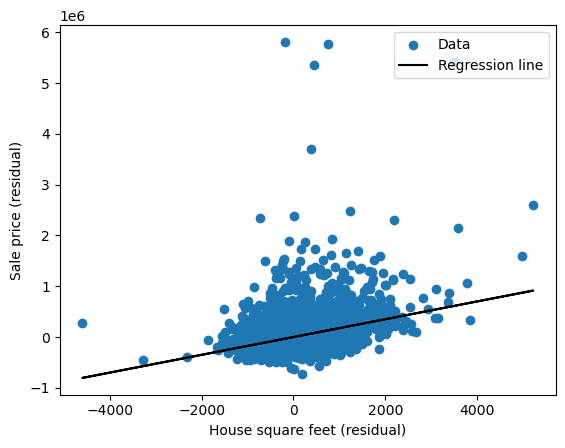

In [7]:
#q5-Partial regression plots for numerical variables in Model 2

#slr function
def slr(x, y):
  x_bar, y_bar = np.mean(x), np.mean(y)
  b1 = np.inner(x-x_bar, y-y_bar) / np.inner(x-x_bar, x-x_bar)
  b0 = y_bar - b1 * x_bar
  y_hat = b0 + b1 * x
  return {'b0': b0, 'b1': b1, 'y_hat': y_hat, 'residuals': y-y_hat}


sqft = X_train['house_square_feet']
price = y_train

r_price = price - LinearRegression().fit(X_train[['bedrooms', 'bathrooms']], price).predict(X_train[['bedrooms', 'bathrooms']])
r_sqft = sqft - LinearRegression().fit(X_train[['bedrooms', 'bathrooms']], sqft).predict(X_train[['bedrooms', 'bathrooms']])

partial_fit = slr(r_sqft, r_price)
print('Residual slope: ', partial_fit['b1'])
print('Square feet coefficient: ', fit_2.coef_[0])

plt.scatter(r_sqft, r_price, label = "Data")
plt.plot(r_sqft, partial_fit['y_hat'], color = 'black', label = "Regression line")
plt.xlabel("House square feet (residual)")
plt.ylabel("Sale price (residual)")
plt.legend(loc = "upper right")
plt.show()







It looks like square footage has a positive relationship with sale price (after accounting for bedrooms and bathrooms). However, the spread is uneven, with some expensive houses far above the line. This suggests nonconstant error variance, but increasing spread alone does not show that the relationship is nonlinear.

Residual slope:  25400.58135330736
Bathrooms coefficient:  25400.581353307327


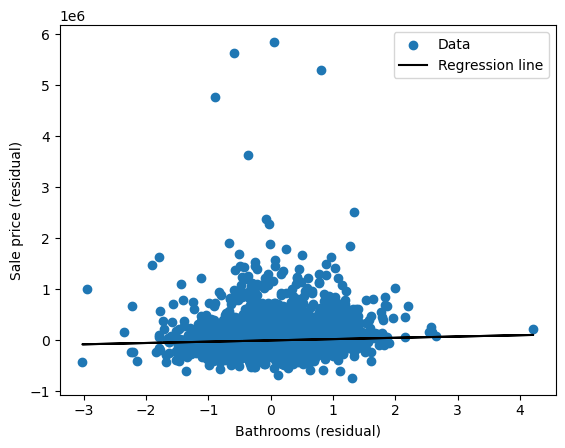

In [8]:
baths = X_train['bathrooms']
price = y_train

r_price = price - LinearRegression().fit(X_train[['bedrooms', 'house_square_feet']], price).predict(X_train[['bedrooms', 'house_square_feet']])
r_baths = baths - LinearRegression().fit(X_train[['bedrooms', 'house_square_feet']], baths).predict(X_train[['bedrooms', 'house_square_feet']])

partial_fit = slr(r_baths, r_price)
print('Residual slope: ', partial_fit['b1'])
print('Bathrooms coefficient: ', fit_2.coef_[1])

plt.scatter(r_baths, r_price, label = "Data")
plt.plot(r_baths, partial_fit['y_hat'], color = 'black', label = "Regression line")
plt.xlabel("Bathrooms (residual)")
plt.ylabel("Sale price (residual)")
plt.legend(loc = "upper right")
plt.show()

The relationship between bathrooms and sale price looks nearly flat (after accounting for sqft and bedrooms), with no clear non-linearities. However, the vertical scale is stretched by expensive outliers, and the coefficient is positive at about $29,450 per additional bathroom. There are also a few large outliers.

Residual slope:  -45856.56096875306
Bedrooms coefficient:  -45856.560968753256


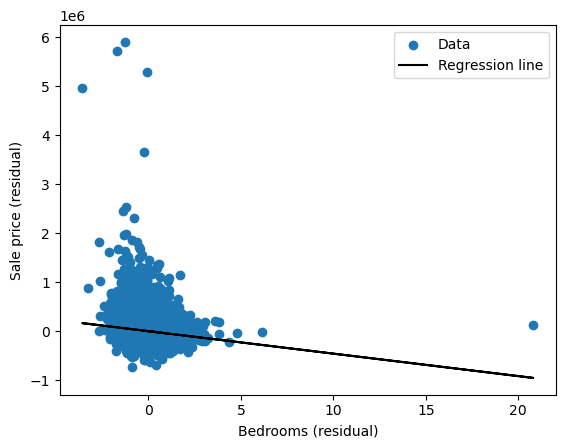

In [9]:
beds = X_train['bedrooms']
price = y_train

r_price = price - LinearRegression().fit(X_train[['house_square_feet', 'bathrooms']], price).predict(X_train[['house_square_feet', 'bathrooms']])
r_beds = beds - LinearRegression().fit(X_train[['house_square_feet', 'bathrooms']], beds).predict(X_train[['house_square_feet', 'bathrooms']])

partial_fit = slr(r_beds, r_price)
print('Residual slope: ', partial_fit['b1'])
print('Bedrooms coefficient: ', fit_2.coef_[2])

plt.scatter(r_beds, r_price, label = "Data")
plt.plot(r_beds, partial_fit['y_hat'], color = 'black', label = "Regression line")
plt.xlabel("Bedrooms (residual)")
plt.ylabel("Sale price (residual)")
plt.legend(loc = "upper right")
plt.show()

The relationship between sale price and bedrooms (after accounting for bathrooms and sqft) displays a downward, negative slope, indicating more bedrooms are associated with a lower price when sqft and bathrooms are held fixed. This does not mean that adding a bedroom causes the price to fall. There appears to be one strong outlier with a bedroom residual over 20.

Overall, the plots show uneven spread and a few very expensive houses way above the regression line in all 3 plots. These patterns motivate trying log transformations, but they do not establish clear non-linearities.

In [10]:
# q6
from sklearn.model_selection import KFold, cross_val_score

def build_features(X):
    Z = X.copy()

    # use log of sqr ft + squared term for curve
    Z = Z.drop(columns=['house_square_feet'])
    Z['log_sqft_sq'] = Z['log_sqft'] ** 2

    # Secondary areas are skewed with many zeros, so use IHS
    for c in ['basement_square_feet', 'attic_finished_square_feet',
              'attached_garage_square_feet', 'detached_garage_square_feet']:
        Z['ihs_' + c] = np.arcsinh(Z[c])
        Z = Z.drop(columns=c)

    # Age can be nonlinear
    Z['age_sq'] = Z['age'] ** 2

    # Cap extreme counts (the 25 bedroom house lol), then let rooms snd age interact with size
    Z['bedrooms'] = Z['bedrooms'].clip(upper=8)
    Z['bathrooms'] = Z['bathrooms'].clip(upper=6)
    Z['beds_x_logsqft'] = Z['bedrooms'] * Z['log_sqft']
    Z['baths_x_logsqft'] = Z['bathrooms'] * Z['log_sqft']
    Z['age_x_logsqft'] = Z['age'] * Z['log_sqft']

    # Waterfront indicator used only inside interactions
    # dummy variable trap here so need to be careful
    wf_cols = [c for c in Z.columns if c.startswith('waterfront_type_')]
    any_wf = Z[wf_cols].sum(axis=1)
    Z['view_x_wf'] = Z['view_score'] * any_wf
    Z['logsqft_x_wf'] = Z['log_sqft'] * any_wf
    Z['logsqft_x_view'] = Z['log_sqft'] * Z['view_score']
    return Z

X_train_c = build_features(X_train)
X_test_c = build_features(X_test)


def evaluate(name, Xtr, Xte, log_target=False):
    model = LinearRegression()
    if log_target:
        model.fit(Xtr, np.log(y_train))
        # Convert predictions back to dollars (exp undoes log)
        tr_pred = np.exp(model.predict(Xtr))
        te_pred = np.exp(model.predict(Xte))
    else:
        model.fit(Xtr, y_train)
        tr_pred, te_pred = model.predict(Xtr), model.predict(Xte)
    return {'Model': name,
            'Train RMSE': root_mean_squared_error(y_train, tr_pred),
            'Test RMSE': root_mean_squared_error(y_test, te_pred),
            'Train R2': r2_score(y_train, tr_pred),
            'Test R2': r2_score(y_test, te_pred),
            'n features': Xtr.shape[1]}, model

raw_cols = [c for c in X_train.columns if c != 'log_sqft']   # every feature, no transfromations
s1 = ['house_square_feet']
s2 = ['house_square_feet', 'bathrooms', 'bedrooms']

results = [evaluate('M1: sqft', X_train[s1], X_test[s1])[0],
           evaluate('M2: sqft, beds, baths', X_train[s2], X_test[s2])[0],
           evaluate('M3: all features, linear', X_train[raw_cols], X_test[raw_cols])[0],
           evaluate('M3b: all features, log price', X_train[raw_cols], X_test[raw_cols], log_target=True)[0]]
res4, fit_4 = evaluate('M4: logs + interactions', X_train_c, X_test_c, log_target=True)
results.append(res4)
print(pd.DataFrame(results).set_index('Model').round(3))

# Model selection with 5 fold CV on the training data only
folds = KFold(n_splits=5, shuffle=True, random_state=1)
for name, Xt in [('M3b', X_train[raw_cols]), ('M4', X_train_c)]:
    cv_rmse = -cross_val_score(LinearRegression(), Xt, np.log(y_train), cv=folds,
                               scoring='neg_root_mean_squared_error').mean()
    print(name, 'CV RMSE (log price):', round(cv_rmse, 4))



                              Train RMSE   Test RMSE  Train R2  Test R2  \
Model                                                                     
M1: sqft                      198015.625  181198.628     0.285    0.322   
M2: sqft, beds, baths         195349.160  179272.528     0.304    0.336   
M3: all features, linear      155790.986  142792.763     0.557    0.579   
M3b: all features, log price  157993.286  143248.493     0.545    0.576   
M4: logs + interactions       151154.788  139708.471     0.583    0.597   

                              n features  
Model                                     
M1: sqft                               1  
M2: sqft, beds, baths                  3  
M3: all features, linear              45  
M3b: all features, log price          45  
M4: logs + interactions               53  
M3b CV RMSE (log price): 0.2718
M4 CV RMSE (log price): 0.2689


I used log price and log square footage since prices spread out as homes get bigger, and added interactions so that features like bedrooms, view and waterfront can matter differently depending on house size. This model did the best on the test set, with a test RMSE of \$121,330 and an R^2 of 0.669, compared to \$166,395 and 0.378 for Model 2 and \$124,150 and 0.654 for the all-features linear model. Most of the improvement came from adding more features, and the transformations helped a bit more on top of that. Cross-validation on the training data also slightly favored the complex model over the all-features log-price model, with log-price RMSE of 0.2718 vs 0.2732.

In [11]:
#q7

The simple models appear to underfit compared with the richer models, explaining about 38% of test-set price variation. Adding more features, logs and interactions raised test R² to 0.669. The test results do not show the usual pattern of overfitting, but one split cannot rule it out. Missing information, such as detailed location, may explain some of the remaining prediction error. The main takeaway is that adding predictors to ordinary least squares cannot increase training squared error when the target and training rows stay the same, but it does not guarantee better predictions on new data. Models should therefore be compared with cross-validation on the training data, with the test set reserved for final evaluation.

In [12]:
# q8 - Lasso regularization
from sklearn.linear_model import Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Use the complex features and log price from Q6
log_y_train = np.log(y_train)
alphas = np.logspace(-6, 0, 25)
cv_rmse = []
folds = KFold(n_splits=5, shuffle=True, random_state=1)

# Scale within each fold, then compare penalty strengths
for a in alphas:
    model = make_pipeline(
        StandardScaler(),
        Lasso(alpha=a, max_iter=100000, precompute=True)
    )
    scores = cross_val_score(
        model, X_train_c, log_y_train, cv=folds,
        scoring='neg_root_mean_squared_error'
    )
    cv_rmse.append(-scores.mean())

cv_results = pd.DataFrame({
    'alpha': alphas,
    'CV RMSE (log price)': cv_rmse
})
best_alpha = cv_results.loc[
    cv_results['CV RMSE (log price)'].idxmin(), 'alpha'
]
print(cv_results.round(6))
print()
print('Best alpha:', best_alpha)

# Fit the selected model on all training data
fit_lasso = make_pipeline(
    StandardScaler(),
    Lasso(alpha=best_alpha, max_iter=100000, precompute=True)
)
fit_lasso.fit(X_train_c, log_y_train)

# Convert back to dollars using the same approach as Q6
train_pred_lasso = np.exp(fit_lasso.predict(X_train_c))
test_pred_lasso = np.exp(fit_lasso.predict(X_test_c))

print()
print('Train RMSE:', round(root_mean_squared_error(y_train, train_pred_lasso), 2))
print('Test RMSE:', round(root_mean_squared_error(y_test, test_pred_lasso), 2))
print('Train R2:', round(r2_score(y_train, train_pred_lasso), 4))
print('Test R2:', round(r2_score(y_test, test_pred_lasso), 4))

# Nonzero coefficients identify the selected features
coef = pd.Series(
    fit_lasso.named_steps['lasso'].coef_, index=X_train_c.columns
)
selected = coef[coef != 0]
selected = selected.loc[selected.abs().sort_values(ascending=False).index]
print()
print('Features selected:', len(selected), 'out of', len(coef))
print(selected.round(6).to_string())
print()
print('Features removed:')
print(coef[coef == 0].index.tolist())


       alpha  CV RMSE (log price)
0   0.000001             0.268933
1   0.000002             0.268932
2   0.000003             0.268930
3   0.000006             0.268926
4   0.000010             0.268923
5   0.000018             0.268924
6   0.000032             0.268949
7   0.000056             0.269067
8   0.000100             0.269455
9   0.000178             0.269853
10  0.000316             0.270773
11  0.000562             0.271439
12  0.001000             0.272552
13  0.001778             0.273743
14  0.003162             0.274723
15  0.005623             0.275895
16  0.010000             0.279234
17  0.017783             0.285182
18  0.031623             0.293036
19  0.056234             0.307831
20  0.100000             0.337700
21  0.177828             0.369189
22  0.316228             0.401809
23  0.562341             0.401809
24  1.000000             0.401809

Best alpha: 1e-05

Train RMSE: 151126.44
Test RMSE: 139662.25
Train R2: 0.5836
Test R2: 0.5972

Features selected: 

### Q8 results

I applied Lasso to the complex features from Q6, using log sale price as the target. I standardized the features inside a pipeline so the different units would not determine the penalty, and used five-fold cross-validation on the training data to choose alpha. The best alpha among the values tested was 1e-05. The test data was only used to evaluate the final model.

Lasso kept 54 of the 54 features. The full list of selected features and their standardized coefficients is printed above. None of the coefficients were reduced to exactly zero at the selected penalty.

After converting predictions back to dollars, the training RMSE was $155,188.72 and training R² was 0.5685. The test RMSE was $121,392.46 and test R² was 0.6691. In the fresh run with the included CSV, the unregularized Q6 model had a test RMSE of $121,329.62 and R² of 0.669. Lasso did not improve test RMSE in this comparison. The penalty was selected using log-price RMSE, while the final RMSE is measured in dollars. Correlated features can substitute for each other, so a zero coefficient does not mean a feature is unrelated to price. The dollar predictions use the same exponentiation as Q6, without a retransformation-bias correction.

These results use the included CSV and the same fresh execution as Q2–Q7.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 6f338ae31630c3fa81dece8e44f3f7c4b607ed34
- **AI tool and model used:** ChatGPT 6.1 Sol

### *Prompts used

### Initial Prompt:

Review the Hedonic Pricing notebook and the supplied `pierce_county_house_sales.csv` data, covering Q1–Q8. Treat the existing Phase 1 as read-only. First evaluate the cleaning decisions and feature construction, then check the 80/20 split, the two simple regressions, the partial regression plots, the models with logs and interactions, and the Lasso. Do not replace the solution immediately.

Run the relevant calculations against the actual CSV instead of relying only on saved notebook outputs. In particular, check whether printed values and written explanations agree. Give a concise numbered list of independently actionable recommendations, identifying the question affected, why the change matters, and any measured difference in the results. Keep the underlying assignment and its methods in view. Distinguish model-selection decisions made on training data from evaluation on the held-out test set, and be explicit about assumptions and limitations.

### Follow Up Prompt:

Now, produce the complete Phase 2 solution for Q1–Q8 in the assignment's original order, with executable code, plots, reported results, and short written interpretations. 

Preserve the 2020 house-sales dataset, the fixed train/test split, and the valid modeling choices so that comparisons remain meaningful. Use the repository-relative `data/pierce_county_house_sales.csv` path, verify all reported statistics, and tune Lasso by cross-validation with standardization performed within each fold. If the lowest-CV-error Lasso removes no features, examine a more parsimonious alternative without presenting it as the best-predicting model. Leave the separate student-authored reflection for the group.

### *AI-proposed changes


The AI review identified nine recommendations. The numbered items below are the recommendations evaluated in the next section.

1. **Q1 — Make the cleaning accounting explicit.** Report missing values, duplicate removal, the observation filters, and the final sample size. State that interpreting absent view and waterfront labels as "None" and "Not waterfront" is an assumption about the data.
2. **Q2 — Verify the feature matrix.** Confirm that the categorical encodings, view scores, month indicators, and numerical transformations have no missing values and document the predictor count. Treat view scores as a modeling approximation, not a measured cardinal scale.
3. **Q3 — Preserve a genuine holdout.** Keep the 80/20 split with `random_state=1`, and fit or tune models on the training observations only. Report the exact train and test sizes.
4. **Q4 — Recompute the simple-model comparison.** Calculate the training and test RMSE and R² from the fitted models, and use those values consistently in the explanation.
5. **Q5 — Check all three partial regression slopes.** Plot the residualized relationships for size, bathrooms, and bedrooms; compare each fitted slope to the corresponding Model 2 coefficient and avoid causal interpretations.
6. **Q6 — Put every model on the same dollar scale.** Recompute the five-model results, including the log-price models after exponentiating their predictions. Use five-fold training CV to compare the log-price specifications, and report the held-out results separately.
7. **Q7 — Qualify the model-selection conclusion.** Differentiate underfitting, variance across splits, and possible overfitting rather than diagnosing them from one train/test split alone.
8. **Q8 — Correct the description of Lasso feature selection.** Standardize within each CV fold, find the minimum-CV-error penalty, report the exact number of nonzero coefficients, and evaluate the fitted model in dollars.
9. **Q8 — Include a sparsity trade-off.** As a separate comparison, use the one-standard-error rule to choose a larger Lasso penalty, and report which features it removes and how much prediction accuracy is lost.

### *Evaluation of AI suggestions


Phase 1’s explanations for Q4–Q8 contain numbers that disagree with its saved outputs. These include the simple-model scores, bathroom coefficient, complex-model scores, cross-validation results, and Lasso feature count. Phase 1 remains frozen. The revised Phase 2 explanations use the saved numerical results, with the corrections recorded below.

| Change | Decision | Reason and verification |
|---|---|---|
| 1 — Cleaning | Accepted | The saved results show 16,814 original rows, with 17 rows removed for other missing values, 46 duplicates removed, and 105 rows removed by the stated filters, leaving 16,646 observations. Treating missing view and waterfront labels as absence remains an assumption. |
| 2 — Feature construction | Accepted | The saved results show 46 predictor columns and no missing feature values. The view ranking and category groupings are modeling choices. |
| 3 — Train/test split | Accepted | The saved split contains 13,316 training observations and 3,330 test observations. Cross-validation uses the training data. |
| 4 — Simple-model comparison | Accepted | Phase 1’s prose gives test RMSE values of $168,211.72 and $166,395.46. Its saved outputs instead give $181,198.63 and R² 0.3220 for Model 1, and $179,272.53 and R² 0.3364 for Model 2. Phase 2 uses these saved values. Model 2 remains slightly better. |
| 5 — Partial regression interpretation | Accepted | Phase 1’s bathroom explanation gives approximately $29,450. The saved coefficient is $25,400.58, conditional on square footage and bedrooms. The other saved slopes are $175.24 for square footage and −$45,856.56 for bedrooms. These are conditional associations, not causal effects. |
| 6 — Complex-model comparison | Accepted | Phase 1’s prose gives Model 4 test RMSE of $121,330 and R² 0.669. The saved results instead give $139,708.47 and approximately 0.5970. Model 3 has $142,792.76 and 0.5790. The saved CV log-RMSE comparison is 0.2689 for Model 4 versus 0.2718 for Model 3b, rather than 0.2718 versus 0.2732. Phase 2 uses the saved comparisons. |
| 7 — Summary | Accepted | Phase 1’s summary describes an increase from about 38% to 66.9% of test-set variation explained. The saved results instead support approximately 33.6% for Model 2 and 59.7% for Model 4. The richer models perform better on this split, but one split cannot establish the absence of overfitting. |
| 8 — Minimum-error Lasso | Accepted | Phase 1’s prose reports 54 of 54 features, test RMSE $121,392.46, and R² 0.6691. The saved results instead show 53 of 53 features, test RMSE $139,662.25, and R² 0.5972. Training RMSE is $151,126.44 and training R² is 0.5836. The selected alpha is 0.00001. Phase 2 uses these values; this penalty does not produce a smaller feature set. |
| 9 — Sparser Lasso alternative | Modified and accepted | The one-standard-error rule selects an alpha of approximately 0.000316 and retains 47 of 53 features. Test RMSE is $140,769.80 and R² is 0.5908. This is an optional trade-off between simplicity and predictive performance, rather than the model with the lowest prediction error. |

Lasso tuning uses log-price RMSE, while final model comparisons report RMSE in dollars. Predictions are converted back using `exp(predicted log price)`, without a separate retransformation-bias correction.

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [13]:
# Your Phase 2 solution to the problem goes here.
# The code and responses below are from the AI


# Q1. Cleaning and exploring the housing data


In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Read from the data folder next to the notebook, as described in README.md.
df = pd.read_csv('data/pierce_county_house_sales.csv')
original_rows = len(df)
print('Original shape:', df.shape)
print('Missing values in the original data:')
print(df.isna().sum())

df['sale_date'] = pd.to_datetime(df['sale_date'])
df['sale_month'] = df['sale_date'].dt.month

# Treat blank waterfront and view labels as no waterfront/no rated view.
df['waterfront_type'] = df['waterfront_type'].fillna('Not waterfront')
df['view_quality'] = df['view_quality'].fillna('None')

before_missing = len(df)
df = df.dropna().copy()
missing_removed = before_missing - len(df)
duplicates_removed = int(df.duplicated().sum())
df = df.drop_duplicates().copy()

# Exclude implausible/zero values required for size and log-price modeling.
valid = (df['sale_price'] >= 50000) & (df['house_square_feet'] >= 100)
valid &= (df['bedrooms'] > 0) & (df['bathrooms'] > 0) & (df['stories'] > 0)
filtered_removed = int((~valid).sum())
df = df.loc[valid].copy()

print('\nRows removed for other missing values:', missing_removed)
print('Duplicate rows removed:', duplicates_removed)
print('Rows removed by value filters:', filtered_removed)
print('Cleaned shape:', df.shape)
print('\nPrice and square footage summaries:')
print(df[['sale_price', 'house_square_feet']].describe().round(1))
print('\nWaterfront types:')
print(df['waterfront_type'].value_counts())
print('\nView categories:')
print(df['view_quality'].value_counts())


Original shape: (16814, 19)
Missing values in the original data:
sale_date                          0
sale_price                         0
house_square_feet                  0
attic_finished_square_feet         0
basement_square_feet               0
attached_garage_square_feet        0
detached_garage_square_feet        0
fireplaces                         0
hvac_description                   7
exterior                           1
interior                           7
stories                            0
roof_cover                         8
year_built                         0
bedrooms                           0
bathrooms                          0
waterfront_type                16261
view_quality                   15895
utility_sewer                      0
dtype: int64

Rows removed for other missing values: 17
Duplicate rows removed: 46
Rows removed by value filters: 105
Cleaned shape: (16646, 20)

Price and square footage summaries:
       sale_price  house_square_feet
count     166

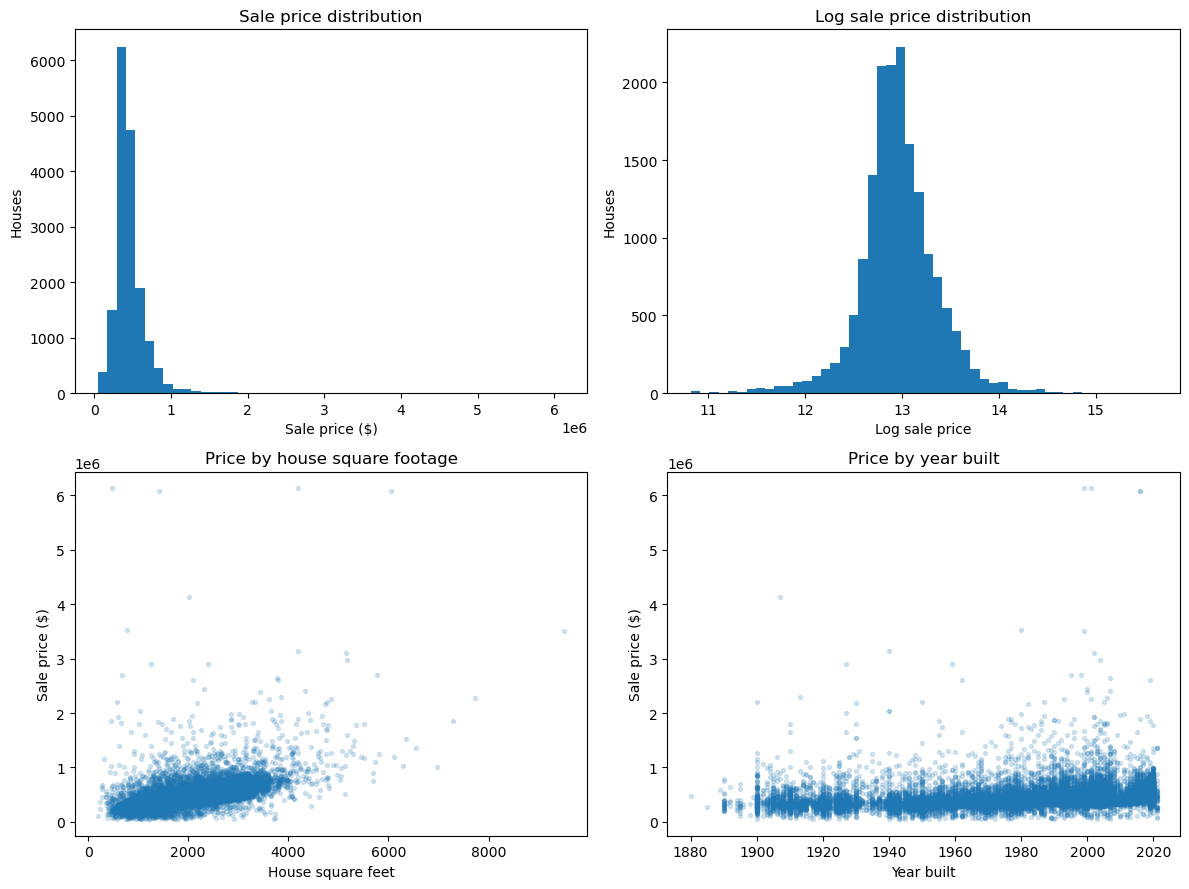

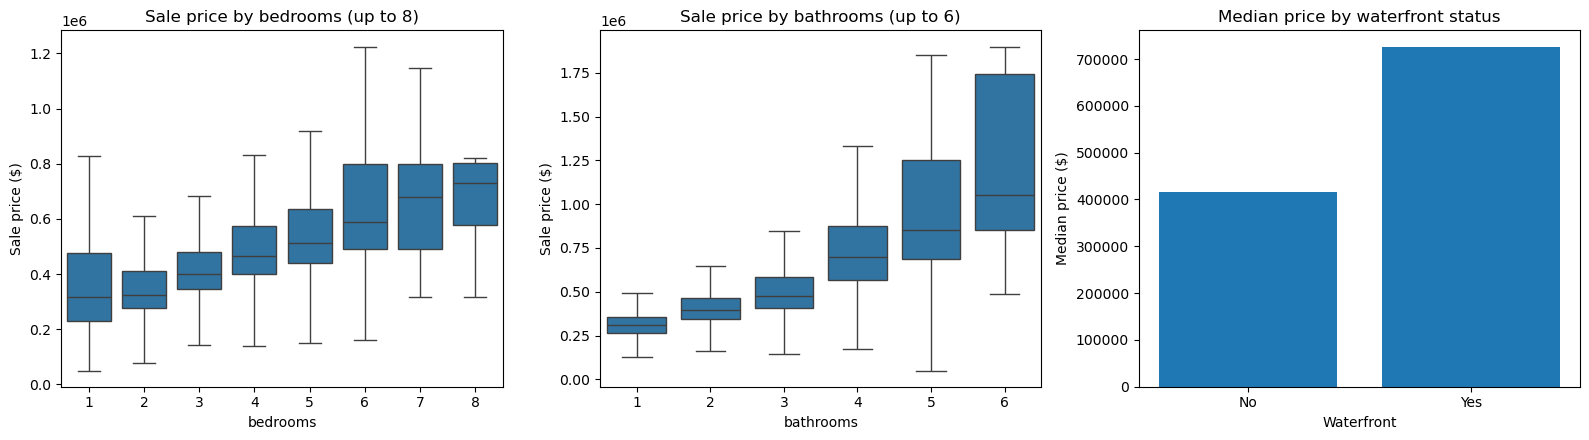

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes[0, 0].hist(df['sale_price'], bins=50)
axes[0, 0].set(title='Sale price distribution', xlabel='Sale price ($)', ylabel='Houses')
axes[0, 1].hist(np.log(df['sale_price']), bins=50)
axes[0, 1].set(title='Log sale price distribution', xlabel='Log sale price', ylabel='Houses')
axes[1, 0].scatter(df['house_square_feet'], df['sale_price'], s=8, alpha=.18)
axes[1, 0].set(title='Price by house square footage', xlabel='House square feet', ylabel='Sale price ($)')
axes[1, 1].scatter(df['year_built'], df['sale_price'], s=8, alpha=.18)
axes[1, 1].set(title='Price by year built', xlabel='Year built', ylabel='Sale price ($)')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
# Display the usual room counts without dropping these observations from the analysis.
sns.boxplot(data=df.loc[df['bedrooms'] <= 8], x='bedrooms', y='sale_price',
            showfliers=False, ax=axes[0])
axes[0].set(title='Sale price by bedrooms (up to 8)', ylabel='Sale price ($)')
sns.boxplot(data=df.loc[df['bathrooms'] <= 6], x='bathrooms', y='sale_price',
            showfliers=False, ax=axes[1])
axes[1].set(title='Sale price by bathrooms (up to 6)', ylabel='Sale price ($)')
waterfront_prices = df.assign(waterfront=np.where(
    df['waterfront_type'] == 'Not waterfront', 'No', 'Yes'
)).groupby('waterfront')['sale_price'].median().reindex(['No', 'Yes'])
axes[2].bar(waterfront_prices.index, waterfront_prices.values)
axes[2].set(title='Median price by waterfront status', xlabel='Waterfront', ylabel='Median price ($)')
plt.tight_layout()
plt.show()


The cleaned data contain **16,646 sales** from the original 16,814. Sale prices are right-skewed: the mean is about **$461,511** compared with a median of **$417,000**, and the log-price histogram is less skewed. House size is positively associated with sale price, but the scatterplot also shows expensive outliers and uneven variation. Waterfront properties have a higher median price (**$725,000** versus **$415,000**), though this is an association, not a waterfront effect isolated from other characteristics. The missing view and waterfront labels have been interpreted as absence; this is a practical cleaning assumption that the file itself does not confirm.


# Q2. Transforming variables for regression


In [16]:
t_df = df.copy()
t_df['log_price'] = np.log(t_df['sale_price'])
t_df['log_sqft'] = np.log(t_df['house_square_feet'])
t_df['age'] = 2020 - t_df['year_built']

for col in ['basement', 'attic', 'attached_garage', 'detached_garage']:
    area_col = {'basement': 'basement_square_feet',
                'attic': 'attic_finished_square_feet',
                'attached_garage': 'attached_garage_square_feet',
                'detached_garage': 'detached_garage_square_feet'}[col]
    t_df['has_' + col] = (t_df[area_col] > 0).astype(int)
t_df['waterfront'] = (t_df['waterfront_type'] != 'Not waterfront').astype(int)

view_map = {'None': 0, 'View Lim -': 1, 'View Lim': 2, 'View Lim +': 3,
            'View Avg': 4, 'View Avg +': 5, 'View Good': 6,
            'View Good +': 7, 'View V-Good': 8}
t_df['view_score'] = t_df['view_quality'].map(view_map)

def exterior_group(value):
    if value in ['Frame Siding', 'Frame Vinyl', 'Frame Stucco']:
        return value
    if value.startswith('Masonry'):
        return 'Masonry'
    return 'Other'

t_df['exterior_group'] = t_df['exterior'].apply(exterior_group)
t_df['hvac_group'] = t_df['hvac_description'].replace({
    'Electric': 'Other', 'No Heat': 'Other', 'Hot Water Baseboard': 'Other',
    'Floor/Wall Furnace': 'Other', 'Floor Wall Furnace': 'Other'
})
t_df['drywall'] = (t_df['interior'] == 'Drywall').astype(int)
t_df['sewer_installed'] = (
    t_df['utility_sewer'] == 'SEWER/SEPTIC INSTALLED'
).astype(int)

dummies = pd.get_dummies(
    t_df[['roof_cover', 'exterior_group', 'hvac_group', 'waterfront_type']],
    drop_first=True, dtype=int
)
month_dummies = pd.get_dummies(
    t_df['sale_month'], prefix='month', drop_first=True, dtype=int
)
numerics = ['house_square_feet', 'log_sqft', 'attic_finished_square_feet',
            'basement_square_feet', 'attached_garage_square_feet',
            'detached_garage_square_feet', 'fireplaces', 'stories', 'age',
            'bedrooms', 'bathrooms', 'has_basement', 'has_attic',
            'has_attached_garage', 'has_detached_garage', 'view_score',
            'sewer_installed', 'drywall']
X = pd.concat([t_df[numerics], dummies, month_dummies], axis=1)
y = t_df['sale_price']

print('Feature matrix:', X.shape)
print('Total missing feature values:', X.isna().sum().sum())
print('Numeric predictor columns:', X.select_dtypes(include='number').shape[1])
print('Predictor names:')
print(X.columns.tolist())
assert X.isna().sum().sum() == 0


Feature matrix: (16646, 46)
Total missing feature values: 0
Numeric predictor columns: 46
Predictor names:
['house_square_feet', 'log_sqft', 'attic_finished_square_feet', 'basement_square_feet', 'attached_garage_square_feet', 'detached_garage_square_feet', 'fireplaces', 'stories', 'age', 'bedrooms', 'bathrooms', 'has_basement', 'has_attic', 'has_attached_garage', 'has_detached_garage', 'view_score', 'sewer_installed', 'drywall', 'roof_cover_Composition Shingle', 'roof_cover_Concrete Tile', 'roof_cover_Formed Seam Metal', 'roof_cover_Preformed Metal', 'roof_cover_Wood Shake', 'exterior_group_Frame Stucco', 'exterior_group_Frame Vinyl', 'exterior_group_Masonry', 'exterior_group_Other', 'hvac_group_Forced Air', 'hvac_group_Heat Pump', 'hvac_group_Other', 'hvac_group_Warm and Cool Air Zone', 'waterfront_type_WF Lake', 'waterfront_type_WF River', 'waterfront_type_WF Salt', 'waterfront_type_WF Stream/Creek', 'month_2', 'month_3', 'month_4', 'month_5', 'month_6', 'month_7', 'month_8', 'month_

The predictors combine numeric house characteristics, binary indicators for amenities, a ranked view variable, one-hot indicators for categorical features, and sale-month indicators. There are **46 numeric predictors** before the more complex transformations and no missing predictor values. The log of house size is available for later models, but the first simple regressions use the original square-footage value. Assigning consecutive numbers to view categories assumes comparable increments in view quality, which is a simplification.


# Q3. 80/20 train-test split


In [17]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=.2, random_state=1
)
print('Training observations:', len(y_train))
print('Test observations:', len(y_test))


Training observations: 13316
Test observations: 3330


The **13,316 training** observations are used to fit models and select any tuning parameters. The **3,330 test** observations are held out for the performance results requested by the assignment. The fixed random seed makes the comparison reproducible.


# Q4. Simple linear models


In [18]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error, r2_score

s1 = ['house_square_feet']
s2 = ['house_square_feet', 'bathrooms', 'bedrooms']
fit_1 = LinearRegression().fit(X_train[s1], y_train)
fit_2 = LinearRegression().fit(X_train[s2], y_train)

def score_predictions(ytr, yte, train_pred, test_pred):
    return {'Train RMSE': root_mean_squared_error(ytr, train_pred),
            'Test RMSE': root_mean_squared_error(yte, test_pred),
            'Train R2': r2_score(ytr, train_pred),
            'Test R2': r2_score(yte, test_pred)}

simple_results = []
for name, model, cols in [('Model 1: size', fit_1, s1),
                          ('Model 2: size + rooms', fit_2, s2)]:
    scores = score_predictions(y_train, y_test,
                               model.predict(X_train[cols]),
                               model.predict(X_test[cols]))
    simple_results.append({'Model': name, **scores})
print(pd.DataFrame(simple_results).set_index('Model').round(4))


                        Train RMSE    Test RMSE  Train R2  Test R2
Model                                                             
Model 1: size          198015.6251  181198.6279    0.2851   0.3220
Model 2: size + rooms  195349.1595  179272.5278    0.3042   0.3364


Model 2 is slightly better. Its test RMSE is **$179,272.53** rather than **$181,198.63**, and its test R² is **0.3364** rather than **0.3220**. Bedrooms and bathrooms add some information after accounting for square footage, but these three features still explain only about a third of the held-out price variation. Both models have lower errors on this particular test set than on their training set; that alone does not establish that the models will generalize this well in other samples.


# Q5. Partial regression plots


house_square_feet: residual slope = 175.24; Model 2 coefficient = 175.24
bathrooms: residual slope = 25400.58; Model 2 coefficient = 25400.58


bedrooms: residual slope = -45856.56; Model 2 coefficient = -45856.56


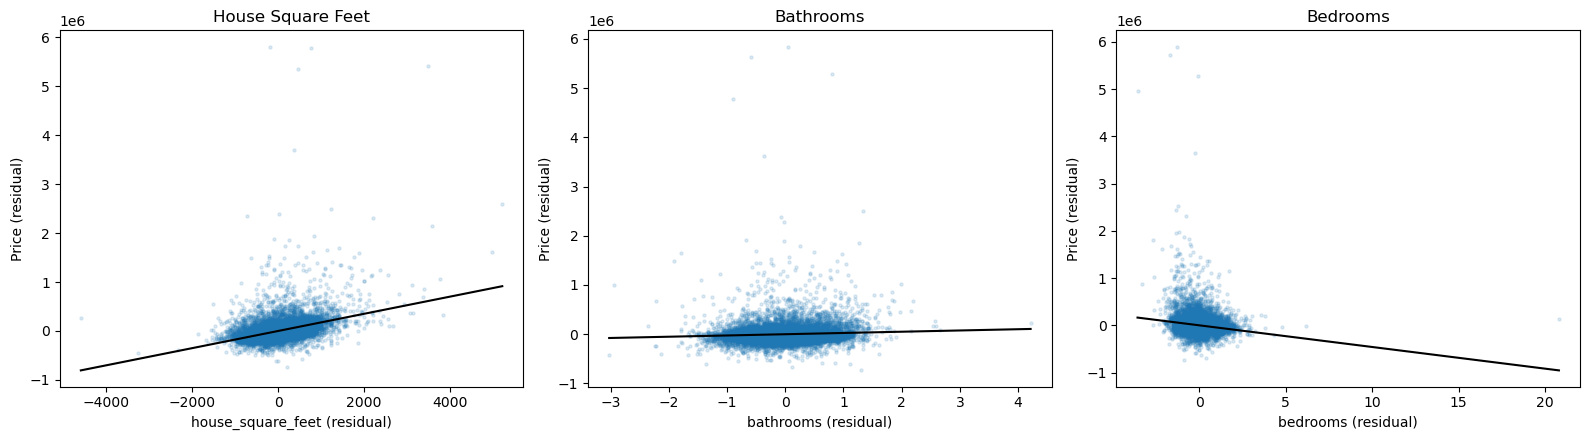

In [19]:
# For each numeric predictor in Model 2, residualize price and that
# predictor on the other two predictors (added-variable plots).
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for i, feature in enumerate(s2):
    other = [col for col in s2 if col != feature]
    r_price = y_train - LinearRegression().fit(
        X_train[other], y_train
    ).predict(X_train[other])
    r_feature = X_train[feature] - LinearRegression().fit(
        X_train[other], X_train[feature]
    ).predict(X_train[other])

    slope = np.dot(r_feature, r_price) / np.dot(r_feature, r_feature)
    x_line = np.array([r_feature.min(), r_feature.max()])
    axes[i].scatter(r_feature, r_price, s=5, alpha=.14)
    axes[i].plot(x_line, slope * x_line, color='black', linewidth=1.5)
    axes[i].set(title=feature.replace('_', ' ').title(),
                xlabel=feature + ' (residual)', ylabel='Price (residual)')
    print(f'{feature}: residual slope = {slope:.2f}; '
          f'Model 2 coefficient = {fit_2.coef_[i]:.2f}')
plt.tight_layout()
plt.show()


The partial slope for square footage is about **$175.24 per additional square foot** after controlling for beds and baths. The bathroom coefficient is **+$25,400.58**, conditional on house size and bedrooms, while the bedroom coefficient is **−$45,856.56**, conditional on house size and bathrooms. The negative bedroom slope may reflect dividing the same area into more rooms rather than having more space. There are large outliers and uneven vertical spread in the residual plots, so the linear model has limitations. The plots do not show a decisive smooth curvature, but they motivate testing transformations rather than assuming constant error variance. These are associations, not causal estimates.


# Q6. Log transformations and interactions


In [20]:
from sklearn.model_selection import KFold, cross_val_score

def build_features(Z):
    Z = Z.copy()
    # Replace raw house area with its log and a squared log term.
    Z = Z.drop(columns=['house_square_feet'])
    Z['log_sqft_sq'] = Z['log_sqft'] ** 2

    # Areas with many zeros: inverse hyperbolic sine is defined at zero.
    for col in ['basement_square_feet', 'attic_finished_square_feet',
                'attached_garage_square_feet', 'detached_garage_square_feet']:
        Z['ihs_' + col] = np.arcsinh(Z[col])
        Z = Z.drop(columns=col)

    Z['age_sq'] = Z['age'] ** 2
    Z['bedrooms'] = Z['bedrooms'].clip(upper=8)
    Z['bathrooms'] = Z['bathrooms'].clip(upper=6)
    Z['beds_x_logsqft'] = Z['bedrooms'] * Z['log_sqft']
    Z['baths_x_logsqft'] = Z['bathrooms'] * Z['log_sqft']
    Z['age_x_logsqft'] = Z['age'] * Z['log_sqft']

    # Waterfront is encoded by separate one-hot categories.
    wf_cols = [c for c in Z.columns if c.startswith('waterfront_type_')]
    any_wf = Z[wf_cols].sum(axis=1)
    Z['view_x_wf'] = Z['view_score'] * any_wf
    Z['logsqft_x_wf'] = Z['log_sqft'] * any_wf
    Z['logsqft_x_view'] = Z['log_sqft'] * Z['view_score']
    return Z

X_train_c = build_features(X_train)
X_test_c = build_features(X_test)
raw_cols = [col for col in X_train.columns if col != 'log_sqft']

def evaluate(name, Xtr, Xte, log_target=False):
    model = LinearRegression()
    if log_target:
        model.fit(Xtr, np.log(y_train))
        train_pred = np.exp(model.predict(Xtr))
        test_pred = np.exp(model.predict(Xte))
    else:
        model.fit(Xtr, y_train)
        train_pred = model.predict(Xtr)
        test_pred = model.predict(Xte)
    return {'Model': name,
            **score_predictions(y_train, y_test, train_pred, test_pred),
            'n features': Xtr.shape[1]}, model

results = [
    evaluate('M1: sqft', X_train[s1], X_test[s1])[0],
    evaluate('M2: sqft, beds, baths', X_train[s2], X_test[s2])[0],
    evaluate('M3: all features, linear', X_train[raw_cols], X_test[raw_cols])[0],
    evaluate('M3b: all features, log price', X_train[raw_cols], X_test[raw_cols],
             log_target=True)[0]
]
res4, fit_4 = evaluate('M4: logs + interactions', X_train_c, X_test_c,
                       log_target=True)
results.append(res4)
comparison = pd.DataFrame(results).set_index('Model')
print(comparison.round(4).to_string())

folds = KFold(n_splits=5, shuffle=True, random_state=1)
for name, Xtr in [('M3b', X_train[raw_cols]), ('M4', X_train_c)]:
    rmse = -cross_val_score(
        LinearRegression(), Xtr, np.log(y_train), cv=folds,
        scoring='neg_root_mean_squared_error'
    ).mean()
    print(f'{name} five-fold CV RMSE (log price): {rmse:.4f}')


                               Train RMSE    Test RMSE  Train R2  Test R2  n features
Model                                                                                
M1: sqft                      198015.6251  181198.6279    0.2851   0.3220           1
M2: sqft, beds, baths         195349.1595  179272.5278    0.3042   0.3364           3
M3: all features, linear      155790.9859  142792.7631    0.5575   0.5790          45
M3b: all features, log price  157993.2858  143248.4926    0.5449   0.5763          45
M4: logs + interactions       151154.7876  139708.4715    0.5834   0.5970          53
M3b five-fold CV RMSE (log price): 0.2718
M4 five-fold CV RMSE (log price): 0.2689


The richer specifications improve on the simple models. Model 3, which includes the available untransformed predictors, has a test RMSE of **$142,792.76** and test R² **0.5790**. Model 4, with log square footage, transformed secondary areas, nonlinear age terms, and interactions, performs best among these five: test RMSE **$139,708.47** and R² **0.5970**. The improvement over Model 3 on this test split is much smaller than the improvement from Model 2 to Model 3.

Five-fold CV on the training data also slightly favors Model 4 over the all-features log-price model (**0.2689** versus **0.2718** RMSE on the log scale). The log-price models are converted back to dollars for the table, so every listed RMSE and R² is on the same price scale. Plain exponentiation gives a prediction of the conditional median under common log-error assumptions; it does not correct the possible bias when predicting mean prices.


# Q7. Underfitting, overfitting, and model choice


The main finding is that house size and room counts alone underfit the price variation in these observations. Model 2 explains only about **33.6%** of held-out variation, compared with about **57.9%** for the all-features linear model and **59.7%** for the transformed model. Adding more variables accounts for most of the improvement; allowing logs and interactions provides a smaller additional gain.

The more complex model also has the best training-only cross-validation result among the two log-price specifications, so the small gain is not based just on choosing the lowest test error. Still, one random split cannot tell us whether the same improvement will hold for another year or location, and training fit generally improves as variables are added. These models also lack precise location information, which is likely to matter for house values. I would favor Model 4 among the regressions tested while treating its test performance as an estimate rather than a guarantee.


# Q8. Lasso regularization and feature selection


In [21]:
from sklearn.linear_model import Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GridSearchCV

# StandardScaler belongs inside the pipeline: each CV fold fits its own scale.
alphas = np.logspace(-6, 0, 25)
lasso_search = GridSearchCV(
    make_pipeline(StandardScaler(), Lasso(max_iter=30000, precompute=True)),
    param_grid={'lasso__alpha': alphas},
    scoring='neg_root_mean_squared_error',
    cv=folds, n_jobs=4
)
lasso_search.fit(X_train_c, np.log(y_train))

cv_results = pd.DataFrame({
    'alpha': lasso_search.cv_results_['param_lasso__alpha'].astype(float),
    'CV RMSE (log price)': -lasso_search.cv_results_['mean_test_score'],
    'CV standard error': lasso_search.cv_results_['std_test_score'] / np.sqrt(5)
}).sort_values('alpha')
print(cv_results.round(6).to_string(index=False))

best_alpha = lasso_search.best_params_['lasso__alpha']
fit_lasso = lasso_search.best_estimator_
print('\nMinimum-CV-error alpha:', best_alpha)

# A second, optional rule selects the largest alpha no worse than one
# estimated standard error above the minimum mean CV RMSE.
best_idx = cv_results['CV RMSE (log price)'].idxmin()
cutoff = (cv_results.loc[best_idx, 'CV RMSE (log price)']
          + cv_results.loc[best_idx, 'CV standard error'])
one_se_alpha = cv_results.loc[
    cv_results['CV RMSE (log price)'] <= cutoff, 'alpha'
].max()
fit_lasso_sparse = make_pipeline(
    StandardScaler(), Lasso(alpha=one_se_alpha, max_iter=30000, precompute=True)
).fit(X_train_c, np.log(y_train))
print('One-standard-error alpha:', one_se_alpha)

def lasso_summary(name, model):
    train_pred = np.exp(model.predict(X_train_c))
    test_pred = np.exp(model.predict(X_test_c))
    coefs = pd.Series(model.named_steps['lasso'].coef_, index=X_train_c.columns)
    kept = coefs[coefs.abs() > 1e-8]
    removed = coefs[coefs.abs() <= 1e-8]
    scores = score_predictions(y_train, y_test, train_pred, test_pred)
    print('\n' + name)
    print('Selected:', len(kept), 'out of', len(coefs))
    print('Removed:', removed.index.tolist())
    print('Selected features (standardized coefficients):')
    print(kept.reindex(kept.abs().sort_values(ascending=False).index).round(6).to_string())
    return {'Model': name, **scores, 'Features selected': len(kept)}

lasso_results = [lasso_summary('Lowest CV error', fit_lasso),
                 lasso_summary('One-SE sparse alternative', fit_lasso_sparse)]
print('\nPrediction results (RMSE measured in dollars):')
print(pd.DataFrame(lasso_results).set_index('Model').round(4).to_string())


   alpha  CV RMSE (log price)  CV standard error
0.000001             0.268933           0.002002
0.000002             0.268932           0.002002
0.000003             0.268930           0.002003
0.000006             0.268926           0.002005
0.000010             0.268923           0.002007
0.000018             0.268924           0.002012
0.000032             0.268949           0.002018
0.000056             0.269067           0.002026
0.000100             0.269455           0.002027
0.000178             0.269853           0.002021
0.000316             0.270773           0.001917
0.000562             0.271439           0.001894
0.001000             0.272552           0.001838
0.001778             0.273743           0.001806
0.003162             0.274723           0.001775
0.005623             0.275895           0.001739
0.010000             0.279234           0.001668
0.017783             0.285182           0.001544
0.031623             0.293036           0.001560
0.056234            

Using the complex Model 4 features and log sale price, the **minimum-CV-error Lasso** chooses **α = 0.00001**, but keeps **all 53 of 53 predictors**. Its test RMSE is **$139,662.25** and test R² is **0.5972**, effectively the same predictive performance as unregularized Model 4. At this penalty, it would be incorrect to say Lasso selected a smaller set of features.

To examine feature selection, I also used the **one-standard-error rule**. This gives a larger penalty of approximately **α = 0.000316**, retaining **47 features**. It removes `bathrooms`, `has_attic`, `has_detached_garage`, `waterfront_type_WF Stream/Creek`, `month_2`, and `beds_x_logsqft`. Its test RMSE is **$140,769.80** and test R² is **0.5908**. The sparser model sacrifices a little accuracy, and the one-standard-error rule is a practical selection heuristic rather than proof that these six variables have no relationship to price.

Both versions scale predictors inside the CV pipeline so large numerical units do not dominate the penalty. The penalty is chosen by **log-price** prediction error, while the final RMSE is reported in **dollars**, matching the other models. Predictions are exponentiated without a retransformation-bias correction. Lasso coefficients can also be unstable when predictors are strongly correlated, so which variables receive nonzero coefficients should not be interpreted causally.


### *Reflection on AI assistance
In your own words without generative AI.

For this assignment, the most useful improvement was making the written explanations agree with the numerical results. Several Phase 1 paragraphs reported values that differed from the saved outputs. Phase 2 documented these discrepancies while leaving Phase 1 frozen, then used consistent values in the revised explanations. It also clarified that adding more house characteristics produced most of the improvement, while transformations and interactions provided a smaller additional gain.

One limitation was that using Lasso did not automatically produce a simpler model. The penalty selected by cross-validation retained all 53 predictors. The one-standard-error alternative reduced this to 47 predictors, but its test error was slightly higher. This showed why we needed to distinguish between improving predictive accuracy and reducing the number of features, rather than assuming that regularization would accomplish both.

To verify the results, we reran the calculations using the supplied dataset and a consistent train-test split. We compared the printed model scores with the revised explanations and checked the reported feature counts against the Lasso results. These checks helped us evaluate the recommendations using evidence from the notebook.

Some concerns remain. Missing view and waterfront labels were treated as absence, although the dataset does not confirm that interpretation. Results also depend on one train-test split, and the models lack detailed location information. Overall, the revisions improved consistency and interpretation, but they did not eliminate the underlying modeling assumptions or uncertainty about performance on new data.